# PSA FIES Microdata Sourcing and Initial Load
**Objective:** Ingest the raw Philippine Statistics Authority (PSA) Family Income and Expenditure Survey (FIES) microdata, verify its structural integrity against the architectural specification (41,544 rows), and generate a schema inventory for Conceptual Data Mapping (Task 1.4).

**Provenance Reference:** See `../docs/data_provenance.md` for dataset source, acquisition date, and SHA-256 hash verification.

--- 
## Imports and Path Configuration

In [3]:
import pandas as pd 
from pathlib import Path 

# Define constants 
EXPECTED_ROWS = 41_544
RAW_DATA_PATH = Path ("../data/raw/fies_raw.csv")
INTERMEDIATE_PATH = Path("../data/intermediate")
SCHEMA_OUTPUT_PATH = INTERMEDIATE_PATH / "files_schema_inventory.csv"

# Ensure dir path exists 
INTERMEDIATE_PATH.mkdir(parents=True, exist_ok=True)

print(f"Target Raw Path: {RAW_DATA_PATH.resolve()}")
print(f"Target Schema Output: {SCHEMA_OUTPUT_PATH.resolve()}")

Target Raw Path: C:\Users\Renz\KilosUnlad\data-pipeline\data\raw\fies_raw.csv
Target Schema Output: C:\Users\Renz\KilosUnlad\data-pipeline\data\intermediate\files_schema_inventory.csv


## Guarded Data Load

In [4]:
if not RAW_DATA_PATH.exists(): 
    raise FileNotFoundError(
        f"Critical Failure: Raw dataset is not found at {RAW_DATA_PATH.resolve()}"
        "Ensure the CSV file is placed in data/raw dir"
    )

print("Loading dataset")
df = pd.read_csv(RAW_DATA_PATH, low_memory=False)

print("Load Successful")
print(f"Dimensions: {df.shape[0]} rows x {df.shape[1]} cols")

Loading dataset
Load Successful
Dimensions: 41544 rows x 60 cols


## Architectural Verification Check

In [5]:
actual_rows = df.shape[0]
actual_cols = df.shape[1]
delta = actual_rows - EXPECTED_ROWS

if delta == 0: 
    print("[PASS] ROW COUNT CHECK: Observed {} rows. Matches the 2015 FIES architectural specification.".format(actual_rows))
else:
    print("[INVESTIGATE] ROW COUNT CHECK: Expected {} rows, but observed {} rows (Delta: {:+d}).".format(EXPECTED_ROWS, actual_rows, delta))
    print("Action Required: Inspect df.head() and df.tail() for duplicate headers, footer metadata, or incorrect survey years before proceeding.")

# Dataset summary 
print("\n[DATASET SUMMARY]")
print("Total Households (Rows): {:,}".format(actual_rows))
print("Total Variables (Cols):  {}".format(actual_cols))

[PASS] ROW COUNT CHECK: Observed 41544 rows. Matches the 2015 FIES architectural specification.

[DATASET SUMMARY]
Total Households (Rows): 41,544
Total Variables (Cols):  60


## Data Study 

In [6]:
print (f"Total Cols: {len(df.columns)}\n")
print("All Col Names:")
for i, col in enumerate(df.columns, 1): 
    print(f"{i:2d}. {col}")

print("\n" + "="*80)
print("INTERACTIVE EXPLORATION TOOL")
print("="*80)
print("To understand a specific column, run the cell below and change the 'target_col' variable.")

Total Cols: 60

All Col Names:
 1. Total Household Income
 2. Region
 3. Total Food Expenditure
 4. Main Source of Income
 5. Agricultural Household indicator
 6. Bread and Cereals Expenditure
 7. Total Rice Expenditure
 8. Meat Expenditure
 9. Total Fish and  marine products Expenditure
10. Fruit Expenditure
11. Vegetables Expenditure
12. Restaurant and hotels Expenditure
13. Alcoholic Beverages Expenditure
14. Tobacco Expenditure
15. Clothing, Footwear and Other Wear Expenditure
16. Housing and water Expenditure
17. Imputed House Rental Value
18. Medical Care Expenditure
19. Transportation Expenditure
20. Communication Expenditure
21. Education Expenditure
22. Miscellaneous Goods and Services Expenditure
23. Special Occasions Expenditure
24. Crop Farming and Gardening expenses
25. Total Income from Entrepreneurial Acitivites
26. Household Head Sex
27. Household Head Age
28. Household Head Marital Status
29. Household Head Highest Grade Completed
30. Household Head Job or Business Ind

In [7]:
import ipywidgets as widgets
from IPython.display import display

def explore_column(col_name): 
    print(f"\n{'='*80}")
    print(f"SEMANTIC EXPLORATION: '{col_name}'")
    print(f"{'='*80}")
        
    print(f"Data Type      : {df[col_name].dtype}")
    print(f"Null Count     : {df[col_name].isna().sum()} ({(df[col_name].isna().mean() * 100):.2f}%)")
    print(f"Unique Values  : {df[col_name].nunique()}")
    
    print(f"\nTop 10 Value Frequencies:")
    display(df[col_name].value_counts(dropna=False).head(10))
    
    print(f"\nSample of first 5 actual values:")
    display(df[col_name].head())

widgets.interact(
    explore_column, 
    col_name=df.columns.tolist()
)

interactive(children=(Dropdown(description='col_name', options=('Total Household Income', 'Region', 'Total Foo…

<function __main__.explore_column(col_name)>

## Schema Inventory Generation 

In [8]:
schema_inventory = pd.DataFrame({
    "column_name": df.columns,
    "dtype": df.dtypes.astype(str),
    "non_null_count": df.count().values,
    "null_percentage": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique().values,
    "sample_value": [str(v)[:60] if pd.notna(v) else "NaN" for v in df.iloc[0]]
})

schema_inventory.to_csv(SCHEMA_OUTPUT_PATH, index=False)
print(f"Schema inventory successfully exported to: {SCHEMA_OUTPUT_PATH.resolve()}")

display(schema_inventory)

Schema inventory successfully exported to: C:\Users\Renz\KilosUnlad\data-pipeline\data\intermediate\files_schema_inventory.csv


,column_name,dtype,non_null_count,null_percentage,unique_values,sample_value
Total Household Income,Total Household Income,int64,41544,0.00,38670,480332
Region,Region,object,41544,0.00,17,CAR
Total Food Expenditure,Total Food Expenditure,int64,41544,0.00,35776,117848
Main Source of Income,Main Source of Income,object,41544,0.00,3,Wage/Salaries
Agricultural Household indicator,Agricultural Household indicator,int64,41544,0.00,3,0
Bread and Cereals Expenditure,Bread and Cereals Expenditure,int64,41544,0.00,26082,42140
Total Rice Expenditure,Total Rice Expenditure,int64,41544,0.00,16145,38300
Meat Expenditure,Meat Expenditure,int64,41544,0.00,18619,24676
Total Fish and marine products Expenditure,Total Fish and marine products Expenditure,int64,41544,0.00,18014,16806
Fruit Expenditure,Fruit Expenditure,int64,41544,0.00,7140,3325


## Col Selction - Filtering

In [9]:
target_columns = [
    "Total Household Income",             # For SWDI Tier Ground Truth (Target Label)
    "Household Head Highest Grade Completed", # Feature 1: head_education_level
    "Main Source of Income",              # Features 2 & 3: head_formal_employment & remittance proxy
    "Total Income from Entrepreneurial Acitivites", # Supplementary income data (note the dataset's typo)
    "Type of Roof",                       # Feature 4: housing_material_score (Part A)
    "Type of Walls",                      # Feature 4: housing_material_score (Part B)
    "Number of Television",               # Feature 5: appliance_density_index
    "Number of Refrigerator/Freezer",     # Feature 5: appliance_density_index
    "Number of Washing Machine",          # Feature 5: appliance_density_index
    "Total Number of Family members",     # Feature 6: dependency_ratio & appliance density
    "Members with age less than 5 year old",  # Feature 6: dependency_ratio
    "Members with age 5 - 17 years old"       # Feature 6: dependency_ratio
]


available_columns = [col for col in target_columns if col in df.columns]
missing_columns = [col for col in target_columns if col not in df.columns]

if missing_columns: 
    print(f"WARNING: The following CDM-mapped columns were NOT found in the dataset: {missing_columns}")
    print("Please update the target_columns list with the exact names from your schema_inventory.")

df_clean = df[available_columns].copy()

print(f"Column Selection Complete.")
print(f"Original shape: {df.shape}")
print(f"Filtered shape: {df_clean.shape}")
print(f"Columns retained: {list(df_clean.columns)}")

Column Selection Complete.
Original shape: (41544, 60)
Filtered shape: (41544, 12)
Columns retained: ['Total Household Income', 'Household Head Highest Grade Completed', 'Main Source of Income', 'Total Income from Entrepreneurial Acitivites', 'Type of Roof', 'Type of Walls', 'Number of Television', 'Number of Refrigerator/Freezer', 'Number of Washing Machine', 'Total Number of Family members', 'Members with age less than 5 year old', 'Members with age 5 - 17 years old']


## Handling Missing Values 

In [10]:
num_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numerical cols to check: {num_cols}")
print(f"Categorial cols to chek: {cat_cols}")

imputation_log = []

for col in num_cols: 
    null_count = df_clean[col].isna().sum()
    if null_count > 0: 
        df_clean[col] = df_clean[col].fillna(0)
        imputation_log.append(f"Filled {null_count} nulls in '{col}' with 0")

for col in cat_cols: 
    null_count = df_clean[col].isna().sum()
    if null_count > 0: 
        mode_val = df_clean[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(mode_val)
        imputation_log.append(f"Filled {null_count} nulls in '{col}' with mode '{mode_val}'")

if imputation_log: 
    print("Imputation Actions taken:")
    for action in imputation_log: 
        print(f"  - {action}")
else:
    print("No missing values found. Dataset is already complete.")

total_nulls = df_clean.isna().sum().sum()
print(f"\nImputation Complete. Total null values remaining: {total_nulls}")

Numerical cols to check: ['Total Household Income', 'Total Income from Entrepreneurial Acitivites', 'Number of Television', 'Number of Refrigerator/Freezer', 'Number of Washing Machine', 'Total Number of Family members', 'Members with age less than 5 year old', 'Members with age 5 - 17 years old']
Categorial cols to chek: ['Household Head Highest Grade Completed', 'Main Source of Income', 'Type of Roof', 'Type of Walls']
No missing values found. Dataset is already complete.

Imputation Complete. Total null values remaining: 0


## Ordinal Encoding

In [11]:
import numpy as np 

roof_mapping = {
    'strong material(galvanized,iron,al,tile,concrete,brick,stone,asbestos)': 3,
    'mixed but predominantly strong materials': 3,
    'mixed but predominantly light materials': 2,
    'light material (cogon,nipa,anahaw)': 1,
    'salvaged/makeshift materials': 1,
    'mixed but predominantly salvaged materials': 1,
    'not applicable': 2
}

wall_mapping = {
    'strong': 3,
    'quite strong': 3,
    'light': 1,
    'very light': 1,
    'salvaged': 1,
    'not applicable': 2
}

def map_material_score(series, mapping_dict): 
    series_str = series.astype(str).str.lower()
    return series_str.map(mapping_dict).fillna(2).astype(int)

if "Type of Roof" in df_clean.columns: 
    print(f"Original Roof cat: {df_clean['Type of Roof'].unique()}")
    df_clean['roof_score'] = map_material_score(df_clean["Type of Roof"], roof_mapping)
    print("Encoded 'Type of Roof' to 'roof_score' \n")

if "Type of Walls" in df_clean.columns: 
    print(f"Original Wall cat: {df_clean['Type of Walls'].unique()}")
    df_clean['wall_score'] = map_material_score(df_clean["Type of Walls"], wall_mapping)
    print("Encoded 'Type of Walls' to 'wall_score' \n")

print("Roof Score Distribution:")
print(df_clean['roof_score'].value_counts().sort_index())
print("\nWall Score Distribution:")
print(df_clean['wall_score'].value_counts().sort_index())

Original Roof cat: ['Strong material(galvanized,iron,al,tile,concrete,brick,stone,asbestos)'
 'Light material (cogon,nipa,anahaw)'
 'Mixed but predominantly strong materials'
 'Mixed but predominantly light materials' 'Salvaged/makeshift materials'
 'Mixed but predominantly salvaged materials' 'Not Applicable']
Encoded 'Type of Roof' to 'roof_score' 

Original Wall cat: ['Strong' 'Light' 'Quite Strong' 'Very Light' 'Salvaged' 'NOt applicable']
Encoded 'Type of Walls' to 'wall_score' 

Roof Score Distribution:
roof_score
1     5342
2      858
3    35344
Name: count, dtype: int64

Wall Score Distribution:
wall_score
1    10306
2       12
3    31226
Name: count, dtype: int64


## Correlation Heatmap

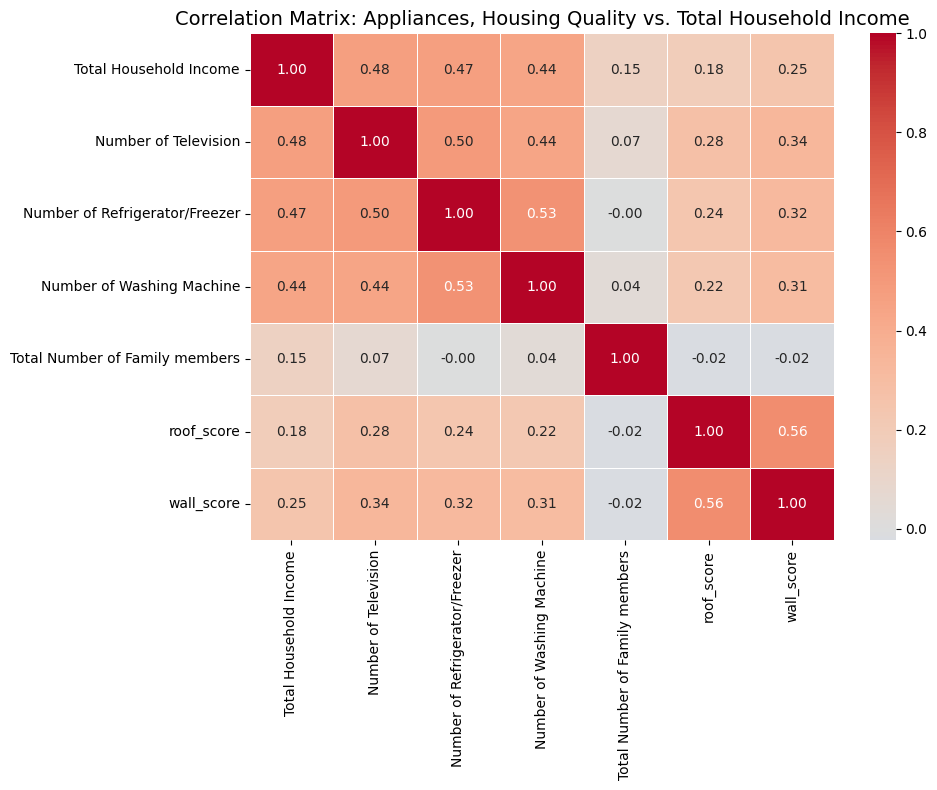

In [12]:
import seaborn as sns 
import matplotlib.pyplot as plt 

heatmap_cols = [
    "Total Household Income", 
    "Number of Television", 
    "Number of Refrigerator/Freezer", 
    "Number of Washing Machine",
    "Total Number of Family members",
    "roof_score", 
    "wall_score"
]

valid_heatmap_cols = [col for col in heatmap_cols if col in df_clean.columns]
corr_matrix = df_clean[valid_heatmap_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, center=0)
plt.title("Correlation Matrix: Appliances, Housing Quality vs. Total Household Income", fontsize=14)
plt.tight_layout()

plt.show()

## EDA Report
---
### Exploratory Data Analysis: Correlation Matrix Interpretation

The Pearson correlation matrix above measures the statistical relationship between our engineered features and the target variable (`Total Household Income`) on a scale from -1.0 to 1.0. 

### 1. Proxy Means Validation (Income vs. Appliances)
The moderate positive correlations between `Total Household Income` and appliance ownership (Television: 0.48, Refrigerator: 0.47, Washing Machine: 0.44) validate the use of **Proxy Means Testing**. 
* **Interpretation:** While richer families tend to own more appliances, the correlation is not perfect (e.g., 0.90). 
* **Architectural Defense:** This proves that income alone is an unreliable indicator of wealth due to underreporting or irregular cash flows. Observable assets are required to build a robust ML model.

### 2. The Housing Paradox (Income vs. Roof/Wall Materials)
The correlation between current income and housing quality is surprisingly weak (`roof_score`: 0.18, `wall_score`: 0.25).
* **Interpretation:** A family's current monthly income does not strictly dictate the physical structure of their home. 
* **Architectural Defense:** This validates the necessity of the **Tier 2 Deterministic Rule Engine**. The ML model (Tier 1) might see a concrete roof and predict high wealth, but the Rule Engine will cross-reference current utility consumption (Electricity/Water) to detect discrepancies, such as a "Sinking Cohort" family living in a legacy concrete home but currently struggling financially, or a low-income family renting a concrete urban apartment.

### 3. Family Size Independence
`Total Number of Family members` shows near-zero correlation with Income (0.15), Appliances (0.07), and Housing (-0.02).
* **Interpretation:** Household size is independent of wealth. A large family can be wealthy (multi-generational business), and a small family can be impoverished.
* **Architectural Defense:** This confirms that Family Size should not be used as a direct wealth predictor. Instead, it is correctly utilized as a denominator to calculate `Per Capita Income` and `Dependency Ratio` in Task 2.2.

### 4. Internal Consistency (Appliance Density)
The strong internal correlations between appliances (e.g., Refrigerator vs. Washing Machine: 0.53) confirm that these variables measure the same underlying latent trait: **Purchasing Power**. This justifies combining them into a single `appliance_density_index` feature for the LightGBM model.

**Conclusion:** No single variable perfectly captures household wealth. This empirical evidence necessitates a multivariate LightGBM approach augmented by a deterministic rule engine to resolve factual discrepancies.

In [13]:
from pathlib import Path

intermediate_path = Path("../data/intermediate")
intermediate_path.mkdir(parents=True, exist_ok=True)

clean_csv_path = intermediate_path / "fies_cleaned_intermediate.csv"
df_clean.to_csv(clean_csv_path, index=False)

print(f"Cleaned dataset successfully exported to: {clean_csv_path.resolve()}")
print("Task 2.1 is officially complete. Close this notebook.")

Cleaned dataset successfully exported to: C:\Users\Renz\KilosUnlad\data-pipeline\data\intermediate\fies_cleaned_intermediate.csv
Task 2.1 is officially complete. Close this notebook.
